In [21]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import mutual_info_classif
import matplotlib.pyplot as plt
import seaborn as sns
from umap import UMAP
import gower

In [22]:
#We will merge the train and test_sets for data processing and for more flexibility when splitting

unsw_train_set = pd.read_csv('dataset/UNSW_NB15_training-set.csv')
unsw_test_set = pd.read_csv('dataset/UNSW_NB15_testing-set.csv')

unsw_set = pd.concat([unsw_train_set, unsw_test_set])

unsw_set[unsw_set['label'] == 1]

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
47911,47912,0.000009,ddp,-,INT,2,0,200,0,111111.107200,...,1,4,0,0,0,2,4,0,Backdoor,1
47912,47913,0.000009,ipv6-frag,-,INT,2,0,200,0,111111.107200,...,2,7,0,0,0,2,7,0,Backdoor,1
47913,47914,0.000009,cftp,-,INT,2,0,200,0,111111.107200,...,1,6,0,0,0,1,6,0,Backdoor,1
47914,47915,0.000003,wsn,-,INT,2,0,200,0,333333.321500,...,2,7,0,0,0,2,6,0,Backdoor,1
47915,47916,0.000008,pvp,-,INT,2,0,200,0,125000.000300,...,1,4,0,0,0,11,4,0,Backdoor,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65847,65848,0.000012,udp,-,INT,2,0,1510,0,83333.330390,...,1,1,0,0,0,1,5,0,Fuzzers,1
65848,65849,20.542910,udp,-,INT,4,0,1216,0,0.146036,...,1,1,0,0,0,1,6,0,Fuzzers,1
65849,65850,20.542910,udp,-,INT,4,0,1216,0,0.146036,...,1,1,0,0,0,1,6,0,Fuzzers,1
65850,65851,0.627022,tcp,-,FIN,10,6,590,268,23.922605,...,1,1,0,0,0,1,5,0,Fuzzers,1


In [23]:
unsw_set.info()

<class 'pandas.DataFrame'>
Index: 257673 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  str    
 3   service            257673 non-null  str    
 4   state              257673 non-null  str    
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dloss              257673 non-null  int64  
 16  sinpkt             

In [24]:
unsw_set.describe()

,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,257673.000000,257673.000000,257673.000000,257673.000000,2.576730e+05,2.576730e+05,2.576730e+05,257673.000000,257673.000000,2.576730e+05,...,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000,257673.000000
mean,72811.823858,1.246715,19.777144,18.514703,8.572952e+03,1.438729e+04,9.125391e+04,180.000931,84.754957,7.060869e+07,...,5.238271,4.032677,8.322964,0.012819,0.012850,0.132005,6.800045,9.121049,0.014274,0.639077
std,48929.917641,5.974305,135.947152,111.985965,1.737739e+05,1.461993e+05,1.603446e+05,102.488268,112.762131,1.857313e+08,...,8.160822,5.831515,11.120754,0.116091,0.116421,0.681854,8.396266,10.874752,0.118618,0.480269
min,1.000000,0.000000,1.000000,0.000000,2.400000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,32210.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.078928e+01,62.000000,0.000000,1.231800e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,64419.000000,0.004285,4.000000,2.000000,5.280000e+02,1.780000e+02,2.955665e+03,254.000000,29.000000,7.439423e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,110923.000000,0.685777,12.000000,10.000000,1.362000e+03,1.064000e+03,1.250000e+05,254.000000,252.000000,8.000000e+07,...,4.000000,3.000000,8.000000,0.000000,0.000000,0.000000,8.000000,11.000000,0.000000,1.000000
max,175341.000000,59.999989,10646.000000,11018.000000,1.435577e+07,1.465753e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,59.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


In [25]:
unsw_set.columns

Index(['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes',
       'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss',
       'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin',
       'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth',
       'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm',
       'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm',
       'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm',
       'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
      dtype='str')

In [26]:
features = pd.read_csv('dataset/UNSW-NB15_features.csv', encoding='cp1252')

features.head()

,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol


In [27]:
#It creates a dictionary which explains each feauture name because they are quite vague
feature_explanations = dict(zip(features['Name'], features['Description']))

feature_explanations['is_sm_ips_ports']

'If source (1) and destination (3)IP addresses equal and port numbers (2)(4)  equal then, this variable takes value 1 else 0'

Text(0, 0.5, 'Frequency')

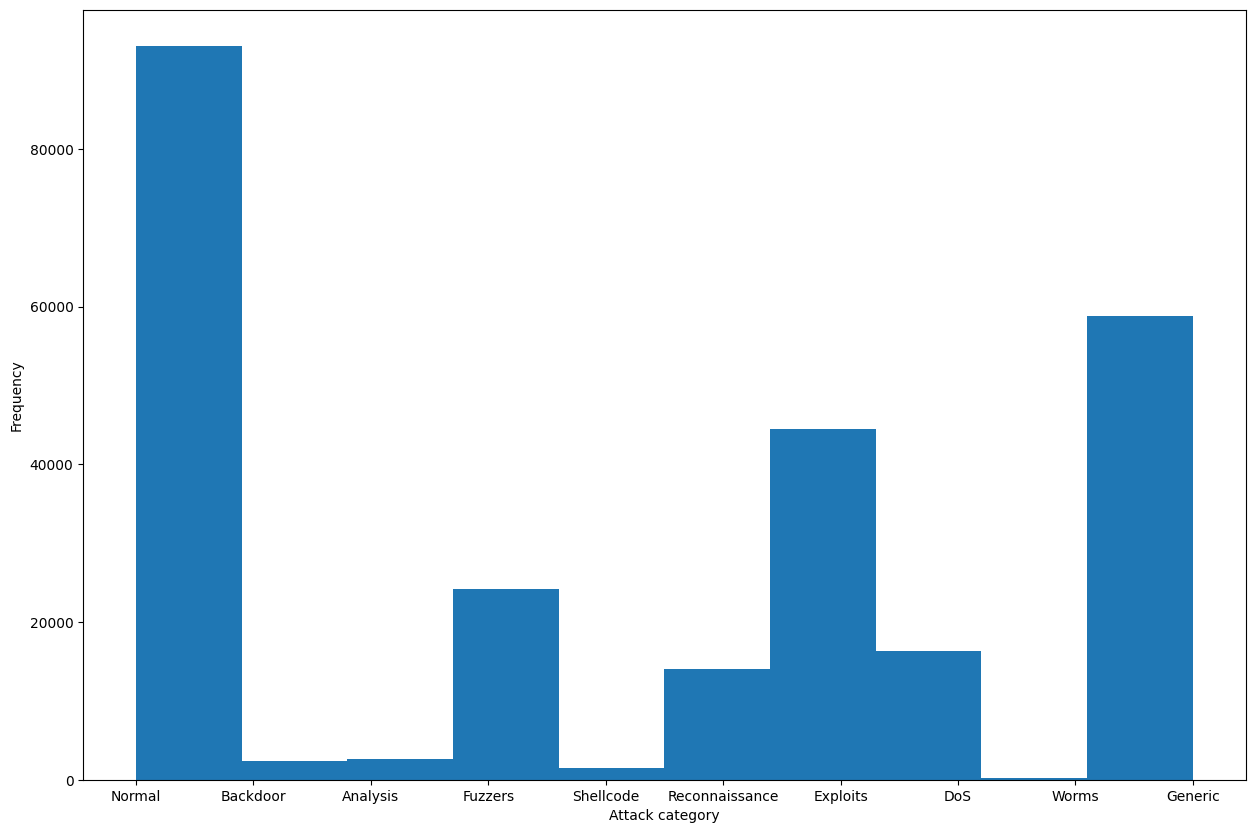

In [28]:
fig = plt.figure(figsize=(15,10))
plt.hist(x = unsw_set['attack_cat'])
plt.xlabel("Attack category")
plt.ylabel("Frequency")

THE REAL MACHINE LEARNING STARTS HERE

MY IDEA FOR THE PIPELINE FOR THE MODEL WHICH DISTINQUISHES BETWEEN ATTACKS AND NORMAL TRAFFIC
1. Split the data into training and testing sets
2. Rank the training data based on information gain and delete useless columns from both train and test sets
3. Fit the OneHotEncoder on the train data and transform the categorical features in both sets
4. Fit the StandardScaler on the train data and transform the numerical features in both sets
5. Merge the processed train and test data
6. Use the IsolationForest to identify and delete outliers in the train data, then drop the same entries in the test data
7. Use UMAP to reduce dimensionality and/or capture nonlinear relationships between feautures
8. Either use only the UMAP components to fit the model or concatenate the UMAP components with the preprocessed train data
9. Fit the model

In [29]:
unsw_set = unsw_set.drop(columns='attack_cat') #We delete attack_cat because this data will be fit to the model
#which only distinquishes between normal traffic and attacks

In [30]:
#Split the data into train, validation and test samples

x_train, x_test, y_train, y_test = train_test_split(unsw_set.drop(columns='label'), unsw_set['label'], test_size=0.2)


#x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.25)

#After that we have 20% as the testing set, 20% as the validation set and 60% as the training set

In [31]:
#Rank the features according to their information gain

#Separate data
categorical_columns = x_train.select_dtypes(include = 'object').columns 

for col in categorical_columns:
    x_train[col] = x_train[col].astype('category').cat.codes #This assigns an integer to each unique category

discrete_mask = x_train.columns.isin(categorical_columns)

information_gain_values = mutual_info_classif(X = x_train, y = y_train, discrete_features = discrete_mask, random_state=42, n_jobs=-1)

information_gain = pd.DataFrame(data = zip(x_train.columns, information_gain_values), columns=['feature', 'information_gain'])

information_gain = information_gain.sort_values(by = ['information_gain'], ascending = False)

information_gain.head()

C:\Users\marci\AppData\Local\Temp\ipykernel_28756\1846172719.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = x_train.select_dtypes(include = 'object').columns


,feature,information_gain
7,sbytes,0.456219
0,id,0.340775
8,dbytes,0.339131
12,sload,0.337824
32,ct_state_ttl,0.334573


In [32]:
#Delete all columns whose information gain is below some threshhold value
threshold_information_gain = 0.05

useless_columns = information_gain['feature'][information_gain['information_gain'] < threshold_information_gain]

x_train = x_train.drop(columns = useless_columns)
x_test = x_test.drop(columns = useless_columns)

useless_columns

30    response_body_len
42      is_sm_ips_ports
29          trans_depth
37         is_ftp_login
38           ct_ftp_cmd
39     ct_flw_http_mthd
Name: feature, dtype: str

In [33]:
#One-hot encode the data


#Set up One-hot encoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

#Fit the encoder on train data and later also transform the test data
encoded_train_data = encoder.fit_transform(x_train[categorical_columns])

#Create dataFrame with encoded categorical features
encoded_train_data_frame = pd.DataFrame(encoded_train_data, columns=encoder.get_feature_names_out(categorical_columns))

encoded_train_data_frame.head()

,proto_0,proto_1,proto_2,proto_3,proto_4,proto_5,proto_6,proto_7,proto_8,proto_9,...,state_0,state_1,state_2,state_3,state_4,state_5,state_6,state_7,state_8,state_9
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


(0.0, 1.0)

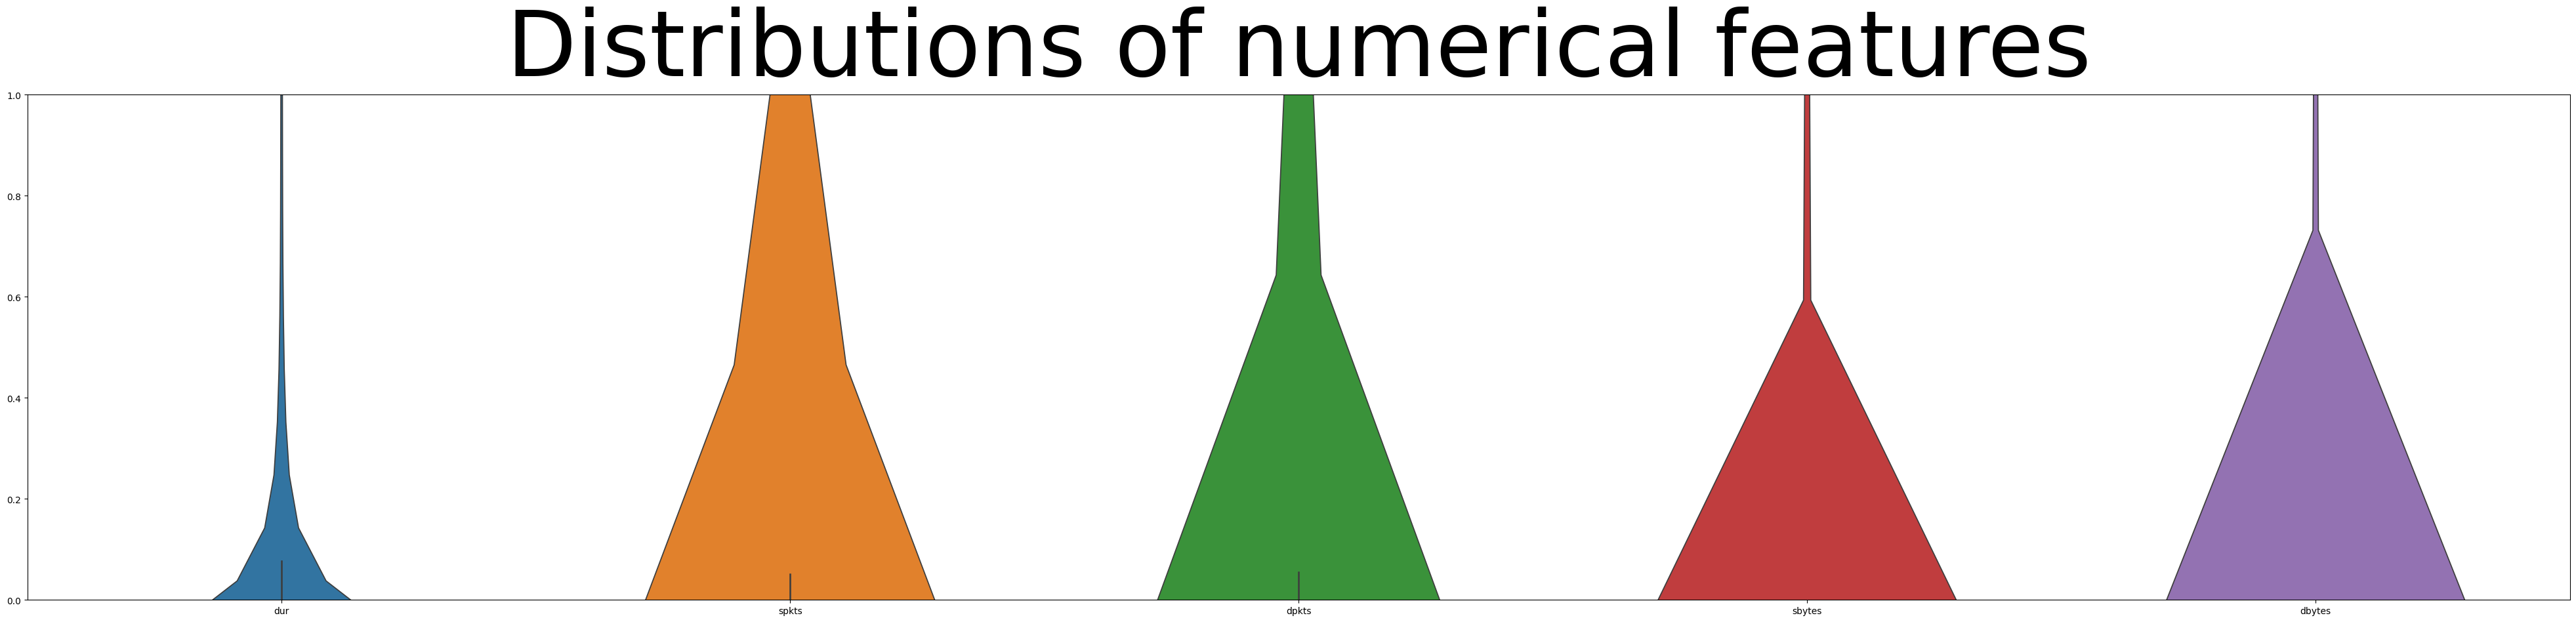

In [34]:
#Select numerical columns which are not fit for scaling
not_scalable_columns = [i for i in ['id', 'is_sm_ips_ports', 'is_ftp_login'] if i not in list(useless_columns)]


numerical_train_data = x_train.drop(columns = list(categorical_columns) + not_scalable_columns)

#Scale the numerical data
scaler = StandardScaler()

#Fit the scaler on the train data and later also transform the test data
numerical_train_data_scaled = scaler.fit_transform(numerical_train_data)

numerical_train_data_frame = pd.DataFrame(numerical_train_data_scaled, columns=numerical_train_data.columns)

plt.figure(figsize=(50,10))
sns.violinplot(data = numerical_train_data_frame.iloc[:,:5])
plt.title("Distributions of numerical features", fontsize=100)
plt.ylim(0,1)



In [35]:
numerical_train_data_frame = numerical_train_data_frame.reset_index(drop=True)
not_scalable_train_data_frame = x_train[not_scalable_columns].reset_index(drop=True)
encoded_train_data_frame = encoded_train_data_frame.reset_index(drop=True)

preprocessed_x_train = pd.concat([numerical_train_data_frame, not_scalable_train_data_frame, encoded_train_data_frame], axis=1)


In [36]:
#Transform the test set using our Scaler and Encoder fit on the train data
numerical_test_data = x_test.drop(columns=list(categorical_columns) + not_scalable_columns)

numerical_test_data_scaled = scaler.transform(numerical_test_data)

encoded_test_data = encoder.transform(x_test[categorical_columns])

numerical_test_data_frame = pd.DataFrame(numerical_test_data_scaled, columns=numerical_test_data.columns)
encoded_test_data_frame = pd.DataFrame(encoded_test_data, columns=encoder.get_feature_names_out(categorical_columns))

numerical_test_data_frame = numerical_test_data_frame.reset_index(drop=True)
not_scalable_test_data_frame = x_test[not_scalable_columns].reset_index(drop=True)
encoded_test_data_frame = encoded_test_data_frame.reset_index(drop=True)

preprocessed_x_test = pd.concat([numerical_test_data_frame, not_scalable_test_data_frame, encoded_test_data_frame], axis=1)

In [45]:
#Use the Isolation Forest to delete outliers from the training data

forest = IsolationForest(contamination=0.01, random_state=42)

#The Isolation Forest chooses features and splits randomly. Because outliers are isolated, it will take on average less splits to completely
#separate them from other data points. The points for which the paths of the Trees are low (the distance from the root node to the leaf)
#are branded as outliers (label = -1)

outlier_train_labels = forest.fit_predict(preprocessed_x_train)

df = pd.DataFrame(outlier_train_labels, columns=['outlier_train_labels'])

df['outlier_train_labels'].value_counts()

#We have detected a lot of outliers

outlier_train_labels
 1    204076
-1      2062
Name: count, dtype: int64

In [46]:
x_train_clean = preprocessed_x_train[outlier_train_labels == 1]
y_train_clean = y_train[outlier_train_labels == 1]

#This is the clean training data to fit to our model

#Now use the forest to delete outliers from the test data

outlier_test_labels = forest.predict(preprocessed_x_test)

x_test_clean = preprocessed_x_test[outlier_test_labels == 1]
y_test_clean = y_test[outlier_test_labels==1]

A couple of plots to understand the data better

Source to destination time to live value 
Destination to source time to live value
No. for each state (6) according to specific range of values for source/destination time to live (10) (11).


array([[<Axes: xlabel='sttl', ylabel='sttl'>,
        <Axes: xlabel='dttl', ylabel='sttl'>,
        <Axes: xlabel='ct_state_ttl', ylabel='sttl'>],
       [<Axes: xlabel='sttl', ylabel='dttl'>,
        <Axes: xlabel='dttl', ylabel='dttl'>,
        <Axes: xlabel='ct_state_ttl', ylabel='dttl'>],
       [<Axes: xlabel='sttl', ylabel='ct_state_ttl'>,
        <Axes: xlabel='dttl', ylabel='ct_state_ttl'>,
        <Axes: xlabel='ct_state_ttl', ylabel='ct_state_ttl'>]],
      dtype=object)

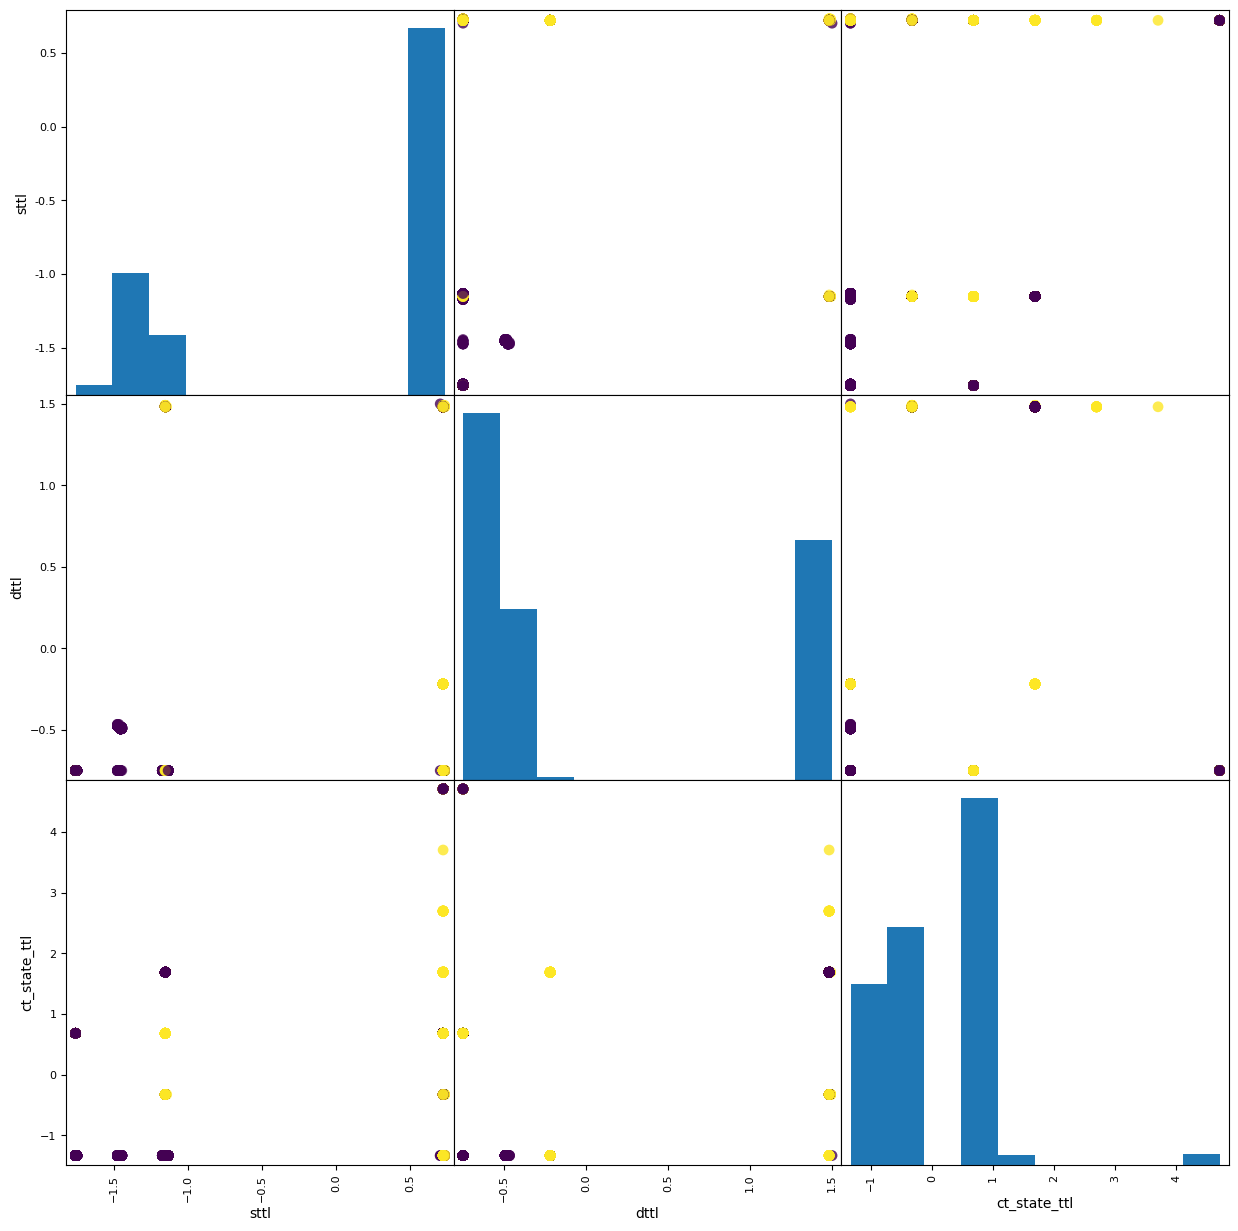

In [47]:
#Select the most informative features from Orange and make a scatter matrix

informative_features = ['sttl', 'dttl', 'ct_state_ttl']


#Explain the features
for feature in informative_features:
    print(feature_explanations[feature])
    
pd.plotting.scatter_matrix(x_train_clean[informative_features], 
                           c=y_train_clean, 
                           figsize=(15,15),
                           marker='0',
                           s=60,
                           alpha=0.8)

([<matplotlib.axis.XTick at 0x150534a0050>,
 [Text(0, 0, '0'), Text(1, 0, '1')])

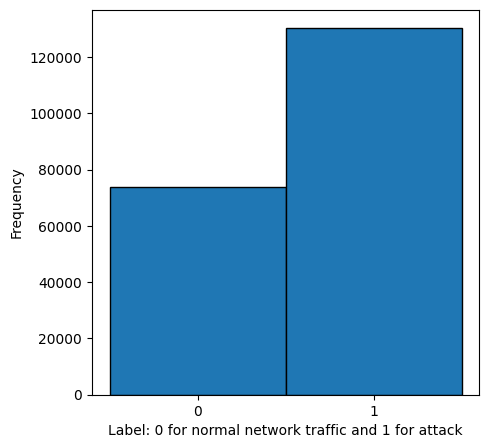

In [48]:
fig = plt.figure(figsize=(5,5))
plt.hist(x = y_train_clean, bins = [-0.5, 0.5, 1.5], edgecolor = 'black')
plt.xlabel("Label: 0 for normal network traffic and 1 for attack")
plt.ylabel("Frequency")
plt.xticks([0,1])

In [49]:
#Now we go back to the original dataset for the umap representation, but excluding outliers

#x_train_original_clean = x_train.loc[outlier_labels == 1].drop(columns=['id'])

#Because out dataset is mixed (it contains numerical and categorical features), we will use the Gower
# distance as the distance between points in the umap representation 
#The distance D_ij = 1-s_ij where s_ij depends on the type of feature
#for categorical features it is simply 1 it the points match and 0 if they dont
#For numerical features it is the range-normalized Manhattan distance

#gower_distances = gower.gower_matrix(x_train_original_clean) 

#THE DATASET IS TO BIG TO CALCULATE GOWER DISTANCES AS IT WOULD TAKE 155 GB OF RAM. 
#WE WILL USE THE PREPROCESSED DATA WITH THE EUCLIDEAN DISTANCE

umap_model = UMAP(
                n_components = 2, 
                n_neighbors = 15, 
                min_dist = 0.1, 
                metric='euclidean', 
                random_state= 42)

X_umap_train = umap_model.fit_transform(x_train_clean.drop(columns=['id'])[:500])

X_umap_train.shape

c:\Users\marci\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(500, 2)

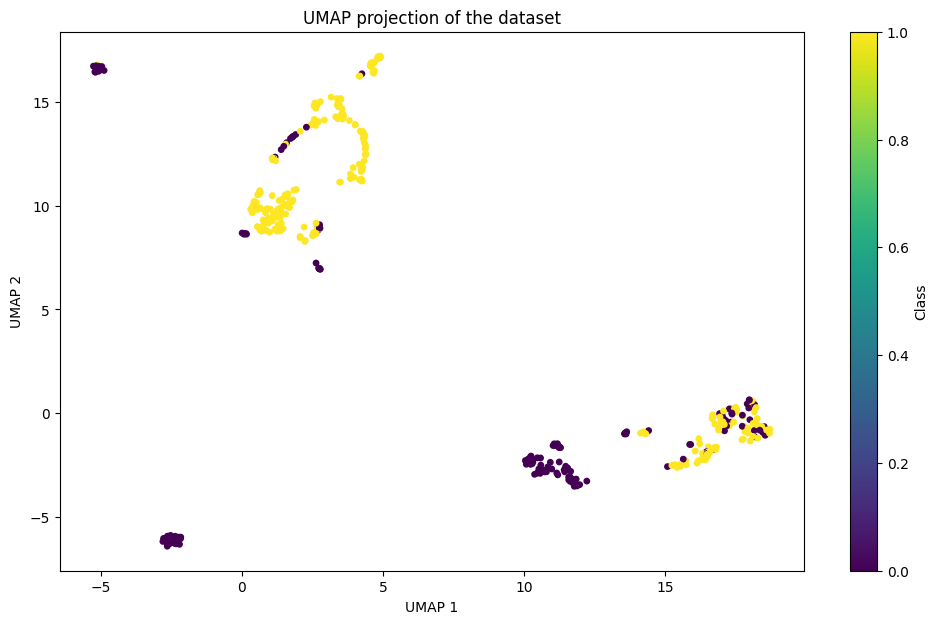

In [ ]:
#Plot the UMAP (only the first 500 points)
plt.figure(figsize=(12,7))

scatter = plt.scatter(
            X_umap_train[:500, 0], 
            X_umap_train[:500, 1], 
            c=y_train_clean[:500], 
            cmap='viridis', 
            s=15)
            
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')

plt.title('UMAP projection of the dataset')


In [ ]:
#Transform the preprocessed test data using the umap which was fitted to the training data

X_umap_test = umap_model.transform(x_test_clean)

#Merge the preprocessed data with the u_map components
x_train_final = np.concatenate([x_train_clean, X_umap_train], axis=1) 
x_test_final = np.concatenate([x_train_clean, X_umap_test], axis=1)